In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [2]:
file_name = "category.csv"
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (259, 14)


,S.No,Country,City,Company,LINKDLN LINK,Website,Tech Need / Problem,EMAIL,CONTACT,Google Map,Category,Cleaned Category,Rating,Review
0,1,India,Maharashtra,MATOSHREE MEDICAL & GENERAL STORES(मातोश्री मेडिकल)- BEST & TOP MEDICAL SHOP/STORE/PHARMACY IN N...,NaN,NaN,NaN,NaN,07414919176,https://maps.app.goo.gl/DaJsWat6tMuka9rG8,Medical Shop,Pharmacy,4.9,72
1,2,India,Gujarat,Ambaji Medical Stores,NaN,NaN,NaN,NaN,09998177155,https://maps.app.goo.gl/2iUVLmXr4YPBuPcD8,Medical Shop,Pharmacy,4.6,11
2,3,India,Gujarat,Gujarat medical store,NaN,NaN,NaN,NaN,02692253927,https://maps.app.goo.gl/4ugMcf67irmfVqa97,Medical Shop,Pharmacy,4.8,10
3,4,India,Delhi,Anand Medical Stores,NaN,NaN,NaN,NaN,01126872323,https://maps.app.goo.gl/gwHi9xcA6q6wh8um8,Medical Shop,Pharmacy,3.4,8
4,5,India,Delhi,Bhardwaj Medical Store,NaN,NaN,NaN,NaN,09782527891,https://maps.app.goo.gl/yebNR3zkR6heYv5VA,Medical Shop,Pharmacy,0.0,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("Data Type").to_frame())

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

print("\nMissing values:")
display(missing_summary)

empty_columns = df.columns[df.isna().all()].tolist()
print("Completely empty columns:", empty_columns if empty_columns else "None")

print("Exact duplicate rows:", int(df.duplicated().sum()))

if "Company" in df.columns:
    normalized_company = (
        df["Company"].fillna("").astype(str).str.strip().str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )
    duplicate_name_mask = normalized_company.ne("") & normalized_company.duplicated(keep=False)
    print("Rows with potentially duplicate company names:", int(duplicate_name_mask.sum()))
    duplicate_cols = [c for c in ["Company", "City", "Category", "Cleaned Category", "Google Map"] if c in df.columns]
    display(df.loc[duplicate_name_mask, duplicate_cols].sort_values("Company"))

if "Rating" in df.columns:
    df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
    invalid_rating = df["Rating"].notna() & ~df["Rating"].between(0, 5)
    print("Ratings outside 0–5:", int(invalid_rating.sum()))

if "Review" in df.columns:
    df["Review"] = pd.to_numeric(df["Review"], errors="coerce")
    print("Negative review counts:", int((df["Review"] < 0).sum()))

    if "Rating" in df.columns:
        zero_rating_and_reviews = df["Rating"].eq(0) & df["Review"].eq(0)
        print("Records with rating 0 and review count 0 (verify availability):",
              int(zero_rating_and_reviews.sum()))

Column names:
['S.No', 'Country', 'City', 'Company', 'LINKDLN LINK', 'Website', 'Tech Need / Problem', 'EMAIL', 'CONTACT', 'Google Map', 'Category', 'Cleaned Category', 'Rating', 'Review']

Data types:


,Data Type
S.No,int64
Country,object
City,object
Company,object
LINKDLN LINK,float64
Website,float64
Tech Need / Problem,float64
EMAIL,float64
CONTACT,object
Google Map,object



Missing values:


,Missing_Count,Missing_Percentage
LINKDLN LINK,259,100.0
Website,259,100.0
EMAIL,259,100.0
Tech Need / Problem,259,100.0
Country,0,0.0
S.No,0,0.0
City,0,0.0
Company,0,0.0
CONTACT,0,0.0
Google Map,0,0.0


Completely empty columns: ['LINKDLN LINK', 'Website', 'Tech Need / Problem', 'EMAIL']
Exact duplicate rows: 0
Rows with potentially duplicate company names: 3


,Company,City,Category,Cleaned Category,Google Map
157,PUNJABI DHABA,Gujarat,Dhaba,Restaurant,https://www.google.com/maps/place/PUNJABI+DHABA+%E0%A4%AA%E0%A4%82%E0%A4%9C%E0%A4%BE%E0%A4%AC%E0...
165,PUNJABI DHABA,Gujarat,Fast Food Restaurant,Restaurant,"https://www.google.com/maps/place/PUNJABI+DHABA/@23.0752217,72.6504788,17z/data=!3m1!4b1!4m6!3m5..."
156,Punjabi Dhaba,Gujarat,Punjabi Restaurant,Restaurant,"https://www.google.com/maps/place/Punjabi+Dhaba/@29.5361,75.7179,17z/data=!3m1!4b1!4m6!3m5!1s0x3..."


Ratings outside 0–5: 0
Negative review counts: 0
Records with rating 0 and review count 0 (verify availability): 14


In [4]:
category_col = "Cleaned Category" if "Cleaned Category" in df.columns else "Category"

if category_col not in df.columns:
    raise ValueError("The CSV must contain 'Cleaned Category' or 'Category'.")

df["Clean_Category"] = (
    df[category_col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
)

# Normalize case/spacing to the canonical category labels used in the rules.
canonical_categories = {
    "clinic": "Clinic",
    "dance academy": "Dance Academy",
    "physiotherapy & rehabilitation": "Physiotherapy & Rehabilitation",
    "restaurant": "Restaurant",
    "stationery shop": "Stationery Shop",
    "automotive services": "Automotive Services",
    "childcare": "Childcare",
    "grocery store": "Grocery Store",
    "hospital": "Hospital",
    "pharmacy": "Pharmacy",
    "computer support and service": "Computer Support and Service",
    "education & tutoring": "Education & Tutoring",
    "music school": "Music School",
    "plant nursery": "Plant Nursery",
    "supermarket": "Supermarket",
    "training school": "Training School"
}

df["Clean_Category"] = df["Clean_Category"].map(
    lambda x: canonical_categories.get(str(x).strip().casefold(), x)
)

print("Category counts:")
display(df["Clean_Category"].value_counts(dropna=False).rename_axis("Category").to_frame("Count"))

expected_categories = set(canonical_categories.values())
observed_categories = set(df["Clean_Category"].dropna().astype(str).unique())
unexpected_categories = sorted(observed_categories - expected_categories)

print("Categories outside the approved list:", unexpected_categories if unexpected_categories else "None")

Category counts:


,Count
Category,
Clinic,46
Pharmacy,42
Stationery Shop,38
Restaurant,30
Grocery Store,23
Physiotherapy & Rehabilitation,15
Music School,13
Automotive Services,11
Hospital,9


Categories outside the approved list: None


In [5]:
high_categories = [
    "Clinic",
    "Dance Academy",
    "Physiotherapy & Rehabilitation",
    "Restaurant",
    "Stationery Shop"
]

medium_categories = [
    "Automotive Services",
    "Childcare",
    "Grocery Store",
    "Hospital",
    "Pharmacy"
]

low_categories = [
    "Computer Support and Service",
    "Education & Tutoring",
    "Music School",
    "Plant Nursery",
    "Supermarket",
    "Training School"
]

priority_score_map = {
    **{category: 0.85 for category in high_categories},
    **{category: 0.65 for category in medium_categories},
    **{category: 0.40 for category in low_categories}
}

df["Priority_Score"] = df["Clean_Category"].map(priority_score_map)

def assign_priority(score):
    if pd.isna(score):
        return "Unmapped - Review Required"
    if score >= 0.75:
        return "High Priority"
    if score > 0.60 and score < 0.75:
        return "Medium Priority"
    if score < 0.60:
        return "Low Priority"
    return "Threshold Review Required"

df["Rule_Based_Priority"] = df["Priority_Score"].apply(assign_priority)

print("Priority score and class counts:")
display(
    df.groupby(["Priority_Score", "Rule_Based_Priority"], dropna=False)
      .size().reset_index(name="Business_Count")
)

print("Unmapped records:", int(df["Priority_Score"].isna().sum()))
if df["Priority_Score"].isna().any():
    display(df.loc[df["Priority_Score"].isna(), [c for c in ["Company", "City", category_col, "Clean_Category"] if c in df.columns]])

Priority score and class counts:


,Priority_Score,Rule_Based_Priority,Business_Count
0,0.40,Low Priority,36
1,0.65,Medium Priority,88
2,0.85,High Priority,135


Unmapped records: 0


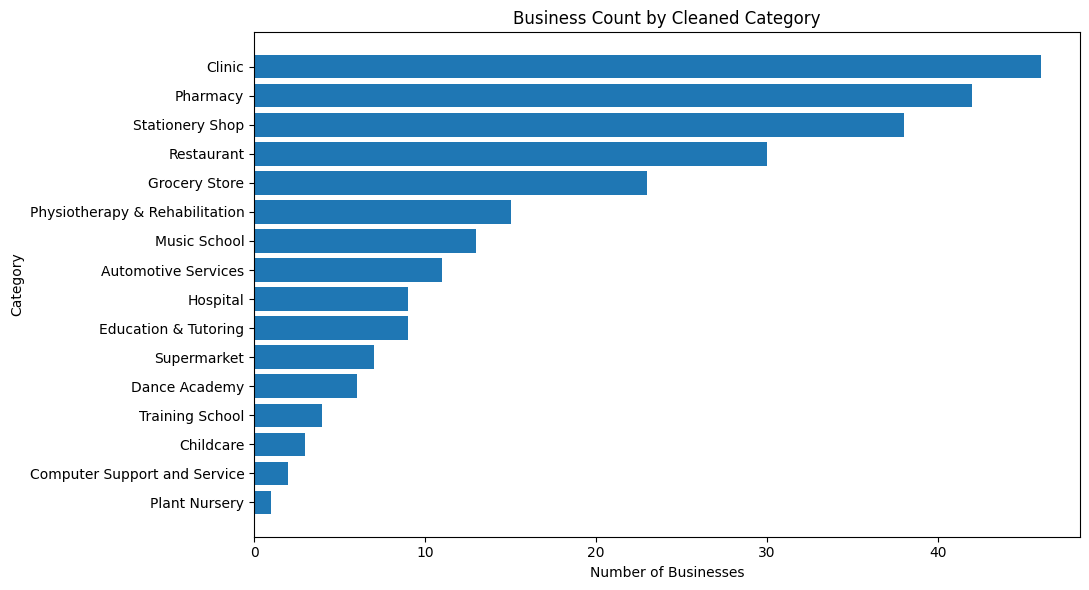

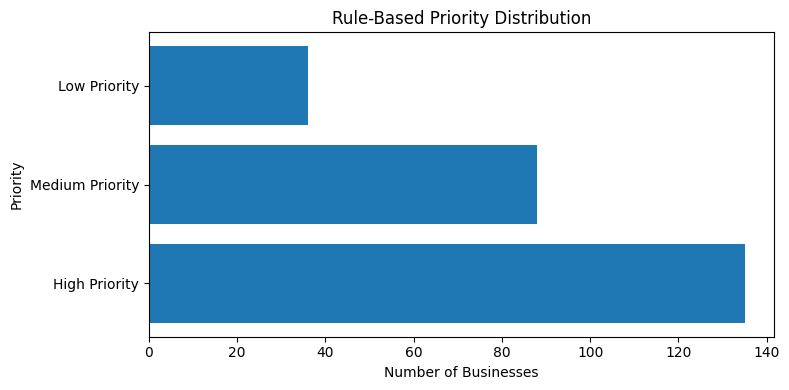

In [6]:
# Category distribution
category_counts = df["Clean_Category"].value_counts().sort_values()
plt.figure(figsize=(11, 6))
plt.barh(category_counts.index.astype(str), category_counts.values)
plt.title("Business Count by Cleaned Category")
plt.xlabel("Number of Businesses")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Priority distribution
priority_order = ["High Priority", "Medium Priority", "Low Priority",
                  "Unmapped - Review Required", "Threshold Review Required"]
priority_counts = df["Rule_Based_Priority"].value_counts().reindex(priority_order, fill_value=0)
priority_counts = priority_counts[priority_counts > 0]

plt.figure(figsize=(8, 4))
plt.barh(priority_counts.index.astype(str), priority_counts.values)
plt.title("Rule-Based Priority Distribution")
plt.xlabel("Number of Businesses")
plt.ylabel("Priority")
plt.tight_layout()
plt.show()

In [7]:
# Only mapped records have a known target label.
model_df = df.loc[df["Priority_Score"].notna()].copy()

model_df["Company_Name_Length"] = (
    model_df["Company"].fillna("").astype(str).str.len()
    if "Company" in model_df.columns else 0
)
model_df["Company_Word_Count"] = (
    model_df["Company"].fillna("").astype(str).str.split().str.len()
    if "Company" in model_df.columns else 0
)

categorical_features = ["Clean_Category"]
if "City" in model_df.columns:
    categorical_features.append("City")

numeric_features = ["Company_Name_Length", "Company_Word_Count"]
feature_columns = categorical_features + numeric_features

X = model_df[feature_columns].copy()
y = model_df["Rule_Based_Priority"].copy()

class_counts = y.value_counts()
print("Target class counts:")
display(class_counts.to_frame("Count"))

if len(class_counts) < 2:
    raise ValueError("Logistic Regression needs at least two priority classes in the mapped data.")
if class_counts.min() < 2:
    raise ValueError(
        "At least one priority class has fewer than 2 rows; a stratified train/test split is not possible. "
        "Review the category mapping or adjust the test split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Target class counts:


,Count
Rule_Based_Priority,
High Priority,135
Medium Priority,88
Low Priority,36


Training rows: 155
Testing rows: 104


In [8]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression training complete.")

Logistic Regression training complete.


In [9]:

# Predict priority class and model confidence

X_all = model_df[feature_columns].copy()

model_df["Model_Predicted_Priority"] = logistic_model.predict(X_all)

probabilities = logistic_model.predict_proba(X_all)

# Highest probability among the available priority classes
model_df["Model_Confidence"] = probabilities.max(axis=1)

# Add only the two model outputs to the main dataframe
df["Model_Predicted_Priority"] = pd.NA
df["Model_Confidence"] = np.nan

df.loc[model_df.index, "Model_Predicted_Priority"] = (
    model_df["Model_Predicted_Priority"]
)

df.loc[model_df.index, "Model_Confidence"] = (
    model_df["Model_Confidence"]
)

# Display the recommended output columns
display(df[[
    "Company",
    "City",
    "Clean_Category",
    "Priority_Score",
    "Rule_Based_Priority",
    "Model_Predicted_Priority",
    "Model_Confidence"
]].head(15))


,Company,City,Clean_Category,Priority_Score,Rule_Based_Priority,Model_Predicted_Priority,Model_Confidence
0,MATOSHREE MEDICAL & GENERAL STORES(मातोश्री मेडिकल)- BEST & TOP MEDICAL SHOP/STORE/PHARMACY IN N...,Maharashtra,Pharmacy,0.65,Medium Priority,Medium Priority,0.629579
1,Ambaji Medical Stores,Gujarat,Pharmacy,0.65,Medium Priority,Medium Priority,0.898630
2,Gujarat medical store,Gujarat,Pharmacy,0.65,Medium Priority,Medium Priority,0.898630
3,Anand Medical Stores,Delhi,Pharmacy,0.65,Medium Priority,Medium Priority,0.931320
4,Bhardwaj Medical Store,Delhi,Pharmacy,0.65,Medium Priority,Medium Priority,0.926961
5,Deepak Medical store,Gujarat,Pharmacy,0.65,Medium Priority,Medium Priority,0.901897
6,Ram Medical Stores,Bangalore,Pharmacy,0.65,Medium Priority,Medium Priority,0.931777
7,Rajat Medical Stores,Maharashtra,Pharmacy,0.65,Medium Priority,Medium Priority,0.935194
8,Shree dwarkadhish medical store,Gujarat,Pharmacy,0.65,Medium Priority,Medium Priority,0.872454
9,METRO CITY PHARMACY,Delhi,Pharmacy,0.65,Medium Priority,Medium Priority,0.933403


In [10]:
comparable = df["Model_Predicted_Priority"].notna()
disagreements = df.loc[
    comparable & (df["Model_Predicted_Priority"] != df["Rule_Based_Priority"]),
    [c for c in [
        "Company", "City", "Clean_Category", "Priority_Score",
        "Rule_Based_Priority", "Model_Predicted_Priority", "Model_Confidence"
    ] if c in df.columns]
]

print("Number of model/rule disagreements:", len(disagreements))
display(disagreements)

category_summary = (
    df.groupby(["Clean_Category", "Priority_Score", "Rule_Based_Priority"], dropna=False)
      .size()
      .reset_index(name="Business_Count")
      .sort_values(["Priority_Score", "Business_Count"], ascending=[False, False])
)

display(category_summary)

Number of model/rule disagreements: 1


,Company,City,Clean_Category,Priority_Score,Rule_Based_Priority,Model_Predicted_Priority,Model_Confidence
111,Vivos Osteopathy,Cambridge,Physiotherapy & Rehabilitation,0.85,High Priority,Low Priority,0.613061


,Clean_Category,Priority_Score,Rule_Based_Priority,Business_Count
2,Clinic,0.85,High Priority,46
13,Stationery Shop,0.85,High Priority,38
12,Restaurant,0.85,High Priority,30
10,Physiotherapy & Rehabilitation,0.85,High Priority,15
4,Dance Academy,0.85,High Priority,6
9,Pharmacy,0.65,Medium Priority,42
6,Grocery Store,0.65,Medium Priority,23
0,Automotive Services,0.65,Medium Priority,11
7,Hospital,0.65,Medium Priority,9
1,Childcare,0.65,Medium Priority,3


In [12]:
csv_output = "Category_Logistic_Regression_Output.csv"
xlsx_output = "Category_Logistic_Regression_Output.xlsx"

df.to_csv(csv_output, index=False)

with pd.ExcelWriter(xlsx_output, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="All Businesses", index=False)
    category_summary.to_excel(writer, sheet_name="Category Summary", index=False)
    missing_summary.to_excel(writer, sheet_name="Data Quality", index=True)

    for priority, sheet_name in [
        ("High Priority", "High Priority"),
        ("Medium Priority", "Medium Priority"),
        ("Low Priority", "Low Priority")
    ]:
        subset = df[df["Rule_Based_Priority"] == priority].sort_values(
            "Priority_Score", ascending=False
        )
        subset.to_excel(writer, sheet_name=sheet_name, index=False)

    
    
print("Files saved:")
print(csv_output)
print(xlsx_output)

Files saved:
Category_Logistic_Regression_Output.csv
Category_Logistic_Regression_Output.xlsx
